# Algorithmic Data Science : Week 3 (Unit 2) lab

## Investigating the run-time of sorting algorithms

We have claimed that the run-time of the insertion_sort algorithm is given by:

$$c_a n^2$$

for a fixed constant $c_a$ when the length $n$ of the list is large. This is an empirical claim, i.e., something which can be verified.  

1) Obtain code for the algorithm (from the lecture notes) and plot the run-time for lists of different lengths (via code from last week's lab). 




In [58]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

root_dir = Path.cwd().parents[1]
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

import aCode.helper as aCode

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [59]:
import matplotlib.pyplot as plt

times = []
emp = [int((i**2)/2) for i in range(100, 500, 50)]

for v in emp:
    print(v)
    t=aCode.timeit(aCode.insertion_sort,aCode.make_rand_list1(v))[0]
    times.append(t)

5000
11250
20000
31250
45000
61250
80000
101250


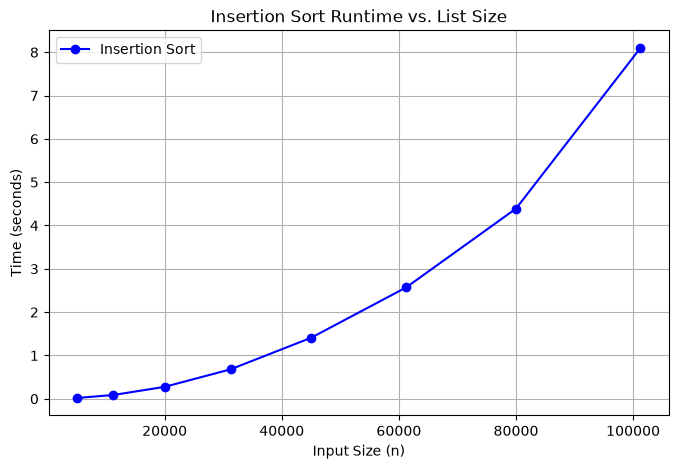

In [60]:
# # Create the plot
plt.figure(figsize=(8, 5))
plt.plot(emp, times, marker='o', linestyle='-', color='b', label='Insertion Sort')

plt.title('Insertion Sort Runtime vs. List Size')
plt.xlabel('Input Size (n)')
plt.ylabel('Time (seconds)')
plt.grid(True)
plt.legend()
plt.show()

2) How can we know we have a quadratic curve $y=c_a x^2$ for insertion_sort and not a curve of $x$ to some other power, $y=c_a x^\alpha$? For this more general case, taking logs of both sides of the equation gives:
$$\log(y) = \log(c_a) + \alpha \log(x)$$
So if we plot the log of the time taken against the log of the length of the list - assuming the function is indeed of the form $y=c_a x^\alpha$, the log-log plot will give us a straight line, and the gradient of this straight line will be $\alpha$ and the $y$ intercept will be $\log(c_a)$.

Create this log-log plot.

In [61]:
import math
ln_emp = [math.log(x) for x in emp]
ln_times = [math.log(x) for x in times]

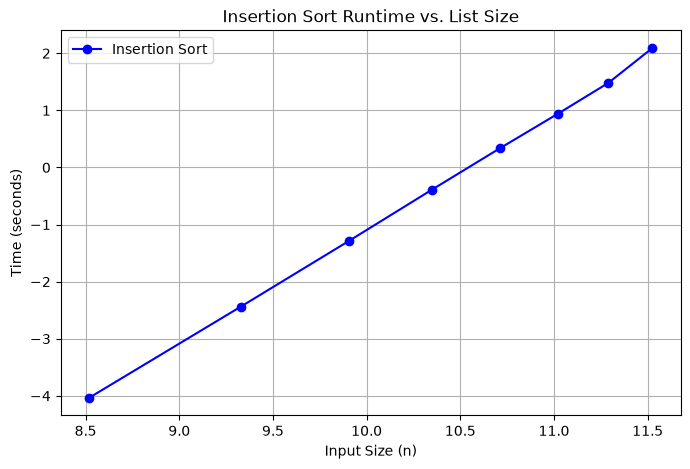

In [62]:
# # Create the plot
plt.figure(figsize=(8, 5))
plt.plot(ln_emp, ln_times, marker='o', linestyle='-', color='b', label='Insertion Sort')

plt.title('Insertion Sort Runtime vs. List Size')
plt.xlabel('Input Size (n)')
plt.ylabel('Time (seconds)')
plt.grid(True)
plt.legend()
plt.show()

3) Can you estimate the constant $c_a$ for your computer? Compare your value of $c_a$ with those of other students. 

(Tip: First estimate the gradient and intercept of the log-log plot using a function from a stats library, and then use that line fit to derive $c_a$. A good choice is the *linregress* function from the library *scipy.stats*. Import the library. Then see how to run the *linregress* function by Googling *scipy.stats.linregress* and reading the documentation for this function.)



In [67]:
import math
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

fit_x = ln_emp
fit_y = ln_times

res = stats.linregress(fit_x, fit_y)

alpha = res.slope
intercept = res.intercept

# Derive ca by inverting the logarithm
ca = math.exp(intercept)

print(f"Estimated alpha (slope): {alpha:.4f}")
print(f"Estimated intercept ln(ca): {intercept:.4f}")
print(f"Estimated constant ca: {ca:.4e} seconds")

Estimated alpha (slope): 2.0155
Estimated intercept ln(ca): -21.2351
Estimated constant ca: 5.9939e-10 seconds


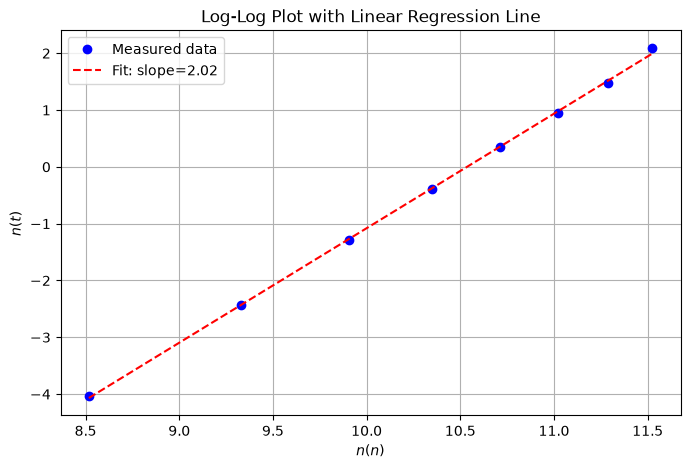

In [68]:
# Generate line values: Y = slope * X + intercept
fit_line = [res.slope * x + res.intercept for x in ln_emp]

plt.figure(figsize=(8, 5))
plt.plot(ln_emp, ln_times, 'bo', label='Measured data')
plt.plot(ln_emp, fit_line, 'r--', label=f'Fit: slope={alpha:.2f}')

plt.title('Log-Log Plot with Linear Regression Line')
plt.xlabel('$n(n)$')
plt.ylabel('$n(t)$')
plt.grid(True)
plt.legend()
plt.show()

4) What value do you get for $\alpha$? If you find $\alpha$ is not that close to 2, it's because the lists you're considering are not long enough for the time complexity to be behaving the way it does asymptotically for large $n$. See what happens to $\alpha$ if you do a plot using longer lists. Do you end up eventually with a value close to 2?

$\alpha$ is 2.01 which approximates the expected value of 2 given the the complexity is $O(n^2)$

5) Recall that the official time complexity should be derived using the worst case scenario. Did you think to use lists that lead to the worst case scenario? If you did plots just based on completely random lists, then you were obtaining average scenarios. Can you do the worst case scenario and the best case scenario? How do these and the average scenario differ?

In [76]:
import numpy as np
import matplotlib.pyplot as plt

test_sizes = [1000, 2000, 4000, 8000, 12000, 16000]

times_best = []
times_avg = []
times_worst = []

for n in test_sizes:
    # 1. Best Case: already sorted
    t_best = aCode.timeit(aCode.insertion_sort, list(range(n)))[0]
    times_best.append(t_best)
    
    # 2. Average Case: random list
    t_avg = aCode.timeit(aCode.insertion_sort, aCode.make_rand_list1(n))[0]
    times_avg.append(t_avg)
    
    # 3. Worst Case: reversed list
    t_worst = aCode.timeit(aCode.insertion_sort, list(range(n, 0, -1)))[0]
    times_worst.append(t_worst)

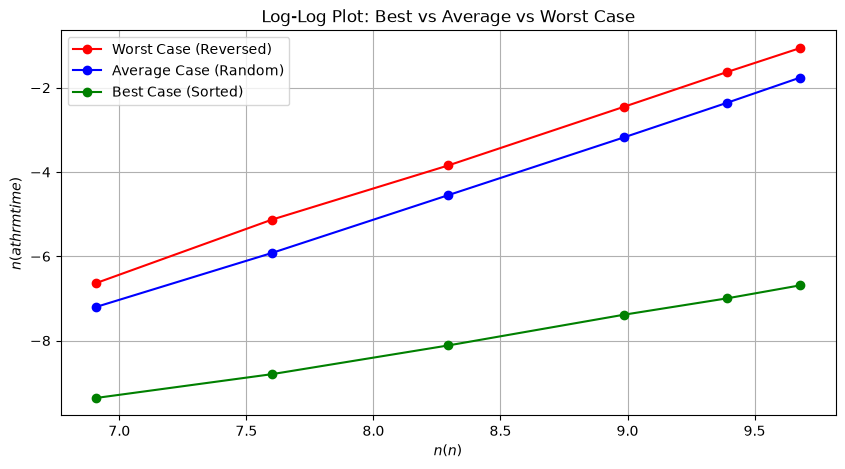

In [77]:
import math
import matplotlib.pyplot as plt

ln_n = [math.log(n) for n in test_sizes]
ln_worst = [math.log(t) for t in times_worst]
ln_avg = [math.log(t) for t in times_avg]
ln_best = [math.log(t) for t in times_best]

plt.figure(figsize=(10, 5))
plt.plot(ln_n, ln_worst, 'r-o', label='Worst Case (Reversed)')
plt.plot(ln_n, ln_avg, 'b-o', label='Average Case (Random)')
plt.plot(ln_n, ln_best, 'g-o', label='Best Case (Sorted)')

plt.title('Log-Log Plot: Best vs Average vs Worst Case')
plt.xlabel('$n(n)$')
plt.ylabel('$n(athrm{time})$')
plt.grid(True)
plt.legend()
plt.show()

**Worst vs Average Case:**
- The fact that the worst and average cases are parrell is proof both functions belong to the exact same complexity set: $O(n^2)$. 
- Both lines have the same power. 
- On a log-log plot, the slope of the line represents the exponent $\alpha$ in $y = c \cdot n^\alpha$
- $\ln(y) = \alpha \ln(n) + \ln(c)$
- Worst case: $T_{\text{worst}}(n) \approx c_{\text{worst}} \cdot n^2 \implies \ln(T) = \mathbf{2} \ln(n) + \ln(c_{\text{worst}})$
- Average case: $T_{\text{avg}}(n) \approx c_{\text{avg}} \cdot n^2 \implies \ln(T) = \mathbf{2} \ln(n) + \ln(c_{\text{avg}})$
- Because both slopes are $2$, the lines are parallel. They grow at the exact same rate; whenever you double $n$, both runtimes quadruple ($2^2 = 4\times$).
- The worst line is higher up because the vertical position is determined by the y-intercept, which equals $\ln(c)$. In the worst case (a fully reversed list), an element must be shifted past all sorted elements before it. In the average case (a random list), an element is shifted past roughly half of the elements before it on average.
- Therefore, the worst-case constant is roughly twice the average-case constant: $c_{\text{worst}} \approx 2 \cdot c_{\text{avg}}$
- That fixed vertical distance between the two parallel lines on your graph is literally the visual representation of $\ln(2)$.
- Both functions are in the same set:

$$O(n^2) = \left\{ T(n) \;\middle\vert{}\; \exists \; c > 0, n_0 > 0 \text{ such that } T(n) \le c \cdot n^2 \text{ for all } n \ge n_0 \right\}$$

---

**Best Case:** 
- The line will be visibly flatter with a slope $\alpha \approx 1$, confirming its linear $O(n)$ behavior.
- The best case is in a different fundamental complexity class—which is why it is not parallel.
- The best-case line has a visibly flatter slope ($\alpha \approx 1$), whereas the average and worst cases have a slope of $\alpha \approx 2$.

---

**Are They in the Same Set? (Big-$O$ vs. Big-$\Theta$)**
- When computer scientists want to identify an algorithm's exact growth family, they use $\Theta$ (Big-Theta):
    - $T_{\text{worst}}(n) \in \mathbf{\Theta(n^2)}$
    - $T_{\text{avg}}(n) \in \mathbf{\Theta(n^2)}$
    - $T_{\text{best}}(n) \in \mathbf{\Theta(n)}$
- Here, the best case is unambiguously in a completely separate set: $\Theta(n) \ne \Theta(n^2)$

---

**The Upper-Bound Definition: Big-$O$:**
- Big-$O$ mathematically means "grows no faster than"
- A linear function $T(n) = c \cdot n$ technically grows slower than $n^2$, so $n \in O(n^2)$ is mathematically true (in the same way that saying "a bicycle is slower than the speed limit of a highway" is true).
- However, $O(n^2)$ is a loose/imprecise upper bound for the best case. The tight, meaningful set for the best case is $O(n)$.

---

**Identifying the power complexity**:
- On a log-log plot, the slope represents the exact exponent $\alpha$ in the power law $y = c \cdot x^\alpha$:
- $\ln(y) = \alpha \ln(x) + \ln(c) \quad \iff \quad Y = \alpha X + C$
- The slope directly identifies the power:
    - Slope $\approx 1$: Linear ($n^1$)
    - Slope $\approx 2$: Quadratic ($n^2$)
    - Slope $\approx 3$: Cubic ($n^3$)
    - Slope $\approx 4$: Quartic ($n^4$)

---

6) (Optional.) How accurate can you make your estimate of $c_a$?  What is the standard deviation / error in your measurements? (Tip: The linear regression function you used has the ability to give you the standard error for the estimates of the slope and intercept.)



7) Repeat your experiments while your computer is heavily loaded (e.g. running some video processing in the background), and compare the results.

(Optional.) Now repeat the whole exercise for the merge_sort algorithm, which we theoretically expect to run in

$$c_bn\log(n)$$

for a fixed constant $c_b$ when the length of the list is large. In this case we cannot (sensibly) log both sides.  However we can use a transformation $x=n \log n$.  If we plot $y$=time-taken against this $x$ then we should get a straight line graph with gradient $c_b$ and $y$-intercept $\approx$ 0.